# Notebook for viewing segmented audio

relative amplitudes between two microphones

In [11]:
session_dir = "../data/birds/GreYel3594M/GreYel3594M___170919_094646"
session_dir = "../data/birds/GreYel3594M/sites/GreYel3594M___170919_094646"

In [12]:
bird, session = session_dir.split("/")[-2:]

In [13]:
try:
    import cPickle as pickle
except ImportError:
    import pickle
    
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import hilbert
import os

from soundsig.signal import lowpass_filter

from segment_analysis import MultiSegment
import block_io
import config

In [14]:
from ipywidgets import interact, widgets
%matplotlib notebook

In [14]:
segmented_data_file = os.path.join(session_dir, "spikes", "{}-sorted-resegmented.pkl").format(session)

In [4]:
with open(segmented_data_file, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(force=True, append=True, recursive=True)

NameError: name 'segmented_data_file' is not defined

In [5]:
block = block_io.load_block(os.path.join(session_dir, "sorted-resegmented.pkl"))

In [15]:
multiseg = MultiSegment(block.segments)

<IPython.core.display.Javascript object>


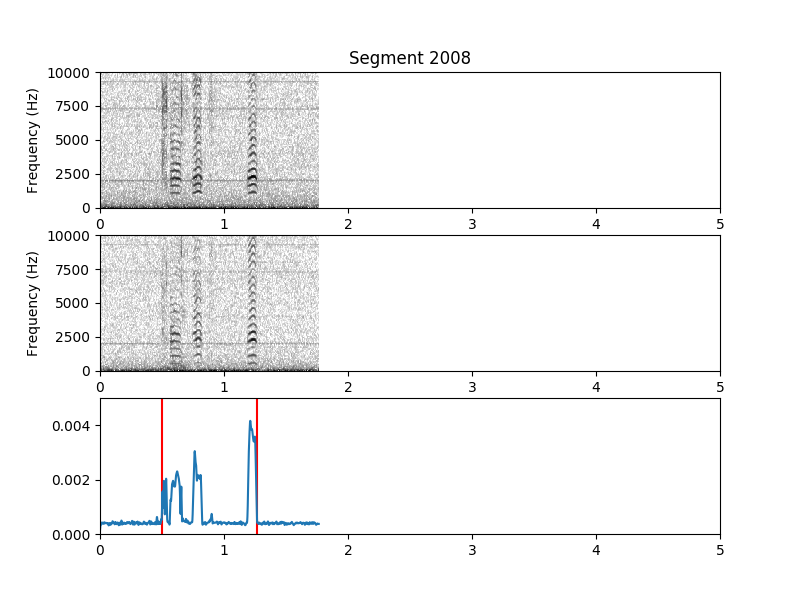

interactive(children=(SelectionSlider(continuous_update=False, description='seg_id', options=(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231, 232, 233, 234, 235, 236, 237, 238, 239, 240, 241, 242, 243, 244, 245, 246, 247, 248, 249, 250, 251, 252, 253, 254, 255, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 267, 268, 269, 270, 271, 272, 273, 274, 275, 276, 277, 278, 279, 280, 281, 282, 283, 284, 285, 286, 287, 288, 289, 290, 291, 292, 293, 294, 295, 296, 297, 298, 299, 300, 301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316, 317, 318, 319, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 332, 333, 334, 335, 336, 337, 338, 339, 340, 341, 342, 343, 344, 345, 346, 347, 348, 349, 350, 351, 352, 353, 354, 355, 356, 357, 358, 359, 360, 361, 362, 363, 364, 365, 366, 367, 368, 369, 370, 371, 372, 373, 374, 375, 376, 377, 378, 379, 380, 381, 382, 383, 384, 385, 386, 387, 388, 389, 390, 391, 392, 393, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 405, 406, 407, 408, 409, 410, 411, 412, 413, 414, 415, 416, 417, 418, 419, 420, 421, 422, 423, 424, 425, 426, 427, 428, 429, 430, 431, 432, 433, 434, 435, 436, 437, 438, 439, 440, 441, 442, 443, 444, 445, 446, 447, 448, 449, 450, 451, 452, 453, 454, 455, 456, 457, 458, 459, 460, 461, 462, 463, 464, 465, 466, 467, 468, 469, 470, 471, 472, 473, 474, 475, 476, 477, 478, 479, 480, 481, 482, 483, 484, 485, 486, 487, 488, 489, 490, 491, 492, 493, 494, 495, 496, 497, 498, 499, 500, 501, 502, 503, 504, 505, 506, 507, 508, 509, 510, 511, 512, 513, 514, 515, 516, 517, 518, 519, 520, 521, 522, 523, 524, 525, 526, 527, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538, 539, 540, 541, 542, 543, 544, 545, 546, 547, 548, 549, 550, 551, 552, 553, 554, 555, 556, 557, 558, 559, 560, 561, 562, 563, 564, 565, 566, 567, 568, 569, 570, 571, 572, 573, 574, 575, 576, 577, 578, 579, 580, 581, 582, 583, 584, 585, 586, 587, 588, 589, 590, 591, 592, 593, 594, 595, 596, 597, 598, 599, 600, 601, 602, 603, 604, 605, 606, 607, 608, 609, 610, 611, 612, 613, 614, 615, 616, 617, 618, 619, 620, 621, 622, 623, 624, 625, 626, 627, 628, 629, 630, 631, 632, 633, 634, 635, 636, 637, 638, 639, 640, 641, 642, 643, 644, 645, 646, 647, 648, 649, 650, 651, 652, 653, 654, 655, 656, 657, 658, 659, 660, 661, 662, 663, 664, 665, 666, 667, 668, 669, 670, 671, 672, 673, 674, 675, 676, 677, 678, 679, 680, 681, 682, 683, 684, 685, 686, 687, 688, 689, 690, 691, 692, 693, 694, 695, 696, 697, 698, 699, 700, 701, 702, 703, 704, 705, 706, 707, 708, 709, 710, 711, 712, 713, 714, 715, 716, 717, 718, 719, 720, 721, 722, 723, 724, 725, 726, 727, 728, 729, 730, 731, 732, 733, 734, 735, 736, 737, 738, 739, 740, 741, 742, 743, 744, 745, 746, 747, 748, 749, 750, 751, 752, 753, 754, 755, 756, 757, 758, 759, 760, 761, 762, 763, 764, 765, 766, 767, 768, 769, 770, 771, 772, 773, 774, 775, 776, 777, 778, 779, 780, 781, 782, 783, 784, 785, 786, 787, 788, 789, 790, 791, 792, 793, 794, 795, 796, 797, 798, 799, 800, 801, 802, 8

<function __main__.amp_env>

In [16]:
fig, axes = plt.subplots(nrows=3, ncols=1, figsize=(8, 6))

segment_slider = widgets.SelectionSlider(
    options=range(len(multiseg.segments)),
    disabled=False,
    continuous_update=False,
    orientation='horizontal',
)

t_slider = widgets.FloatSlider(value=5.0, min=0, max=10.0, step=0.1, disabled=False, continuous_update=False,
    orientation='horizontal',
    readout=True,
    readout_format='.1f',
)

last_seg = -1
def amp_env(seg_id=0, t_max=5.0):
    global last_seg
    if last_seg != seg_id:
        last_seg = seg_id
        for ax in axes:
            ax.clear()
        axes[0].set_title("Segment {}".format(seg_id))
        multiseg.plotter.plot_spectrogram(seg_id, signal=0, channel=0, ax=axes[0])
        multiseg.plotter.plot_spectrogram(seg_id, signal=0, channel=1, ax=axes[1])
        t_arr, sound, sr = multiseg.get_amplitude_envelope(seg_id, signal=0)
#         sound = sound - np.mean(sound, axis=0)
#         sound = lowpass_filter(np.abs(hilbert(sound)).T, sr, 100).T
        plt.plot(t_arr, sound[:, 0])
#         print np.diff(np.abs(hilbert(sound - np.mean(sound, axis=0))), axis=1)
#         axes[2].plot(t_arr, np.diff(np.abs(hilbert(sound - np.mean(sound, axis=0))), axis=1))
        print(multiseg.segments[seg_id].annotations)
    for ax in axes:
        ax.set_xlim(0, t_max)
    axes[-1].set_ylim(0, 0.005)
    axes[-1].vlines([0.5, t_arr[-1] - 0.5], *axes[-1].get_ylim(), "r")

    fig.canvas.draw()
    
interact(amp_env, seg_id = segment_slider, t_max = t_slider)


In [41]:
block.channel_indexes

[ChannelIndex with  name: 'ADC',
 ChannelIndex with  name: 'EventData',
 ChannelIndex with 4 units name: 'Amp Elec 0',
 ChannelIndex with 5 units name: 'Amp Elec 1',
 ChannelIndex with 7 units name: 'Amp Elec 2',
 ChannelIndex with 5 units name: 'Amp Elec 3',
 ChannelIndex with 3 units name: 'Amp Elec 4',
 ChannelIndex with 3 units name: 'Amp Elec 5',
 ChannelIndex with 3 units name: 'Amp Elec 6',
 ChannelIndex with 3 units name: 'Amp Elec 7',
 ChannelIndex with 3 units name: 'Amp Elec 8',
 ChannelIndex with 5 units name: 'Amp Elec 9',
 ChannelIndex with 6 units name: 'Amp Elec 10',
 ChannelIndex with 4 units name: 'Amp Elec 11',
 ChannelIndex with 4 units name: 'Amp Elec 12',
 ChannelIndex with 5 units name: 'Amp Elec 13',
 ChannelIndex with 6 units name: 'Amp Elec 14',
 ChannelIndex with 5 units name: 'Amp Elec 15']

In [ ]:
block = suss.io.read_pickle("../data/birds/BroGre4497M/sites/BroGre4497M_180608_161511/thresholded.pkl")